<a href="https://colab.research.google.com/github/SiyaDalal/Banking-DWM-Project/blob/member_2/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import os

file_path = "/content/lendingclub.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("-" * 40)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values — top 15 columns:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

Dataset loaded successfully!
----------------------------------------
Total rows: 75127
Total columns: 151

First 5 records:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'a

,0
member_id,75127
sec_app_num_rev_accts,75127
sec_app_open_act_il,75127
sec_app_inq_last_6mths,75127
sec_app_open_acc,75127
sec_app_mort_acc,75127
sec_app_mths_since_last_major_derog,75127
sec_app_collections_12_mths_ex_med,75127
sec_app_chargeoff_within_12_mths,75127
sec_app_fico_range_low,75127


In [ ]:
# CELL 2: DATA QUALITY AND LOAN STATUS ANALYSIS
# Purpose:
# 1. Check the distribution of loan statuses.
# 2. Identify missing target values.
# 3. Count duplicate records.
# 4. Find columns with more than 50% missing values.
# 5. Inspect important loan-related features.

# 1. Check loan status distribution
print("Loan Status Distribution:")
display(df["loan_status"].value_counts(dropna=False))

# 2. Check missing loan status values
print("\nMissing loan_status values:")
print(df["loan_status"].isnull().sum())

# 3. Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Calculate missing value percentages
missing_percent = (df.isnull().mean() * 100).sort_values(
    ascending=False
)

print("\nColumns with more than 50% missing values:")
display(missing_percent[missing_percent > 50])

# 5. Inspect important loan-related columns
important_cols = [
    "loan_amnt",
    "int_rate",
    "grade",
    "purpose",
    "issue_d",
    "loan_status"
]

display(df[important_cols].head(10))

Loan Status Distribution:


,count
loan_status,
Fully Paid,52546
Charged Off,13460
Current,8563
Late (31-120 days),337
In Grace Period,163
Late (16-30 days),56
Default,1
NaN,1



Missing loan_status values:
1

Duplicate rows: 0

Columns with more than 50% missing values:


,0
member_id,100.000000
sec_app_num_rev_accts,100.000000
sec_app_open_act_il,100.000000
sec_app_inq_last_6mths,100.000000
sec_app_open_acc,100.000000
sec_app_mort_acc,100.000000
sec_app_mths_since_last_major_derog,100.000000
sec_app_collections_12_mths_ex_med,100.000000
sec_app_chargeoff_within_12_mths,100.000000
sec_app_fico_range_low,100.000000


,loan_amnt,int_rate,grade,purpose,issue_d,loan_status
0,3600.0,13.99,C,debt_consolidation,Dec-2015,Fully Paid
1,24700.0,11.99,C,small_business,Dec-2015,Fully Paid
2,20000.0,10.78,B,home_improvement,Dec-2015,Fully Paid
3,35000.0,14.85,C,debt_consolidation,Dec-2015,Current
4,10400.0,22.45,F,major_purchase,Dec-2015,Fully Paid
5,11950.0,13.44,C,debt_consolidation,Dec-2015,Fully Paid
6,20000.0,9.17,B,debt_consolidation,Dec-2015,Fully Paid
7,20000.0,8.49,B,major_purchase,Dec-2015,Fully Paid
8,10000.0,6.49,A,credit_card,Dec-2015,Fully Paid
9,8000.0,11.48,B,credit_card,Dec-2015,Fully Paid


In [ ]:
# CELL 3: PREPARE THE LOAN DEFAULT MODELLING DATASET
# Purpose:
# 1. Keep only loans with confirmed outcomes: Fully Paid or Charged Off.
# 2. Create a binary target column named default_flag.
# 3. Remove columns that contain no useful data.
# 4. Display the resulting dataset shape and target distribution.
# 5. Check for missing values in the selected dataset.

# Keep only records with confirmed loan outcomes
model_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

# Create binary target: 1 = Charged Off, 0 = Fully Paid
model_df["default_flag"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)

# Remove columns that are completely empty
empty_cols = model_df.columns[
    model_df.isnull().all()
].tolist()

model_df.drop(columns=empty_cols, inplace=True)

# Display dataset information
print("Modelling dataset prepared.")
print("Rows and columns:", model_df.shape)
print("\nTarget distribution:")
display(model_df["default_flag"].value_counts())

print("\nTarget distribution in percentage:")
display(
    (model_df["default_flag"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nCompletely empty columns removed:", len(empty_cols))
print("Remaining columns:", model_df.shape[1])

print("\nTop 15 columns by missing-value count:")
display(
    model_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

Modelling dataset prepared.
Rows and columns: (66006, 137)

Target distribution:


,count
default_flag,
0,52546
1,13460



Target distribution in percentage:


,proportion
default_flag,
0,79.61
1,20.39



Completely empty columns removed: 15
Remaining columns: 137

Top 15 columns by missing-value count:


,0
desc,65999
orig_projected_additional_accrued_interest,65718
dti_joint,65713
annual_inc_joint,65712
verification_status_joint,65712
hardship_status,65607
hardship_amount,65607
hardship_reason,65607
payment_plan_start_date,65607
hardship_length,65607


In [ ]:
# CELL 4: IDENTIFY POTENTIAL DATA LEAKAGE AND UNSUITABLE FEATURES
# Purpose:
# 1. Identify columns related to loan outcomes and repayment.
# 2. Identify columns with very high missing-value percentages.
# 3. Inspect available columns for feature selection.
# 4. Preserve model_df without dropping any additional columns yet.

# Potential outcome and repayment-related columns
outcome_keywords = [
    "recover", "collection", "last_pymnt",
    "next_pymnt", "total_pymnt", "out_prncp",
    "settlement", "hardship", "chargeoff",
    "charged_off", "last_credit_pull"
]

potential_leakage = [
    col for col in model_df.columns
    if any(keyword in col.lower() for keyword in outcome_keywords)
]

print("Potential outcome-related columns:")
print(potential_leakage)

# Calculate missing-value percentages
missing_pct = model_df.isnull().mean().mul(100).sort_values(
    ascending=False
)

print("\nColumns with more than 50% missing values:")
display(missing_pct[missing_pct > 50].to_frame("Missing_Percent"))

# Display all available columns in groups for inspection
print("\nAll available columns:")
for start in range(0, len(model_df.columns), 25):
    print(model_df.columns[start:start + 25].tolist())

Potential outcome-related columns:
['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'chargeoff_within_12_mths', 'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 'hardship_amount', 'hardship_start_date', 'hardship_end_date', 'hardship_length', 'hardship_dpd', 'hardship_loan_status', 'hardship_payoff_balance_amount', 'hardship_last_payment_amount', 'debt_settlement_flag', 'debt_settlement_flag_date', 'settlement_status', 'settlement_date', 'settlement_amount', 'settlement_percentage', 'settlement_term']

Columns with more than 50% missing values:


,Missing_Percent
desc,99.989395
orig_projected_additional_accrued_interest,99.563676
dti_joint,99.556101
annual_inc_joint,99.554586
verification_status_joint,99.554586
hardship_status,99.395509
hardship_amount,99.395509
hardship_reason,99.395509
payment_plan_start_date,99.395509
hardship_length,99.395509



All available columns:
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs']
['earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high']
['last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 't

In [ ]:
# CELL 5: FEATURE SELECTION AND DATA LEAKAGE REMOVAL
# Purpose:
# 1. Select loan application and borrower-related features.
# 2. Exclude loan repayment and post-origination information.
# 3. Remove identifiers and high-missingness columns.
# 4. Preserve the target variable default_flag.
# 5. Display the selected features and dataset dimensions.

# Features available at or around loan origination
selected_features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "earliest_cr_line",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type",
    "mort_acc",
    "pub_rec_bankruptcies",
    "tax_liens",
    "issue_d"
]

# Keep only features that exist in the dataset
selected_features = [
    col for col in selected_features
    if col in model_df.columns
]

# Build a separate modelling dataframe
loan_model = model_df[selected_features + ["default_flag"]].copy()

# Remove rows with missing target values, if any
loan_model = loan_model.dropna(subset=["default_flag"])

# Report selected features
print("Selected feature count:", len(selected_features))
print("Selected features:")
print(selected_features)

print("\nModelling dataset shape:", loan_model.shape)

print("\nMissing values in selected features:")
display(
    loan_model.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nTarget distribution:")
display(loan_model["default_flag"].value_counts())

Selected feature count: 28
Selected features:
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'tax_liens', 'issue_d']

Modelling dataset shape: (66006, 29)

Missing values in selected features:


,0
emp_length,4228
revol_util,31
dti,2
term,0
int_rate,0
grade,0
installment,0
home_ownership,0
sub_grade,0
annual_inc,0



Target distribution:


,count
default_flag,
0,52546
1,13460


In [ ]:
# CELL 6: DATA PREPROCESSING AND TRAIN-TEST SPLIT
# Purpose:
# 1. Separate input features (X) and target (y).
# 2. Identify numerical and categorical columns.
# 3. Impute missing values using suitable strategies.
# 4. One-hot encode categorical features and scale numerical features.
# 5. Split the data into stratified training and testing sets.
# 6. Fit preprocessing only on the training data to prevent data leakage.

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate features and target
X = loan_model.drop(columns=["default_flag"]).copy()
y = loan_model["default_flag"].astype(int)

# Convert issue date and earliest credit line to date-derived features
for col in ["issue_d", "earliest_cr_line"]:
    if col in X.columns:
        dates = pd.to_datetime(X[col], format="%b-%Y", errors="coerce")
        X[col + "_year"] = dates.dt.year
        X[col + "_month"] = dates.dt.month
        X.drop(columns=[col], inplace=True)

# Treat all remaining object columns as categorical
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# Split before fitting imputers, encoders, or scalers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nTraining records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining target distribution:")
display(y_train.value_counts())

print("\nTesting target distribution:")
display(y_test.value_counts())

Numerical features: 21
Categorical features: 9

Training records: 52804
Testing records: 13202
Processed training shape: (52804, 145)
Processed testing shape: (13202, 145)

Training target distribution:


,count
default_flag,
0,42036
1,10768



Testing target distribution:


,count
default_flag,
0,10510
1,2692


In [ ]:
# CELL 7: TRAIN AND COMPARE LOAN DEFAULT CLASSIFICATION MODELS
# Purpose:
# 1. Train Logistic Regression, Decision Tree, and Random Forest.
# 2. Generate predictions on unseen test data.
# 3. Calculate accuracy, precision, recall, F1-score, and ROC-AUC.
# 4. Display a comparison table to evaluate the models.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import pandas as pd

# Define the three classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train models and evaluate test predictions
results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

    print(f"{name} training completed.")

# Display model comparison
results_df = pd.DataFrame(results).sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training Random Forest...
Random Forest training completed.

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6694,0.3423,0.6738,0.4540,0.7375
1,Random Forest,0.7282,0.3807,0.5308,0.4434,0.7312
2,Decision Tree,0.6454,0.3130,0.6185,0.4157,0.6565


In [ ]:
# CELL 7: TRAIN AND COMPARE SYLLABUS CLASSIFICATION MODELS
# Purpose:
# 1. Train Logistic Regression and Decision Tree.
# 2. Predict loan default on the test dataset.
# 3. Evaluate both models using standard classification metrics.
# 4. Compare results without Random Forest.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Define models included in our syllabus
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    )
}

# Train and evaluate each model
results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

# Display final comparison
results_df = pd.DataFrame(results).sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))


Training Logistic Regression...

Training Decision Tree...

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6694,0.3423,0.6738,0.4540,0.7375
1,Decision Tree,0.6454,0.3130,0.6185,0.4157,0.6565



CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

  Fully Paid       0.89      0.67      0.76     10510
 Charged Off       0.34      0.67      0.45      2692

    accuracy                           0.67     13202
   macro avg       0.62      0.67      0.61     13202
weighted avg       0.78      0.67      0.70     13202



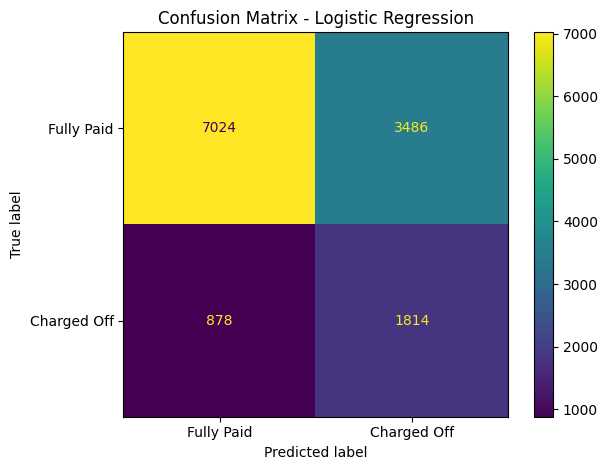


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

  Fully Paid       0.87      0.65      0.75     10510
 Charged Off       0.31      0.62      0.42      2692

    accuracy                           0.65     13202
   macro avg       0.59      0.64      0.58     13202
weighted avg       0.76      0.65      0.68     13202



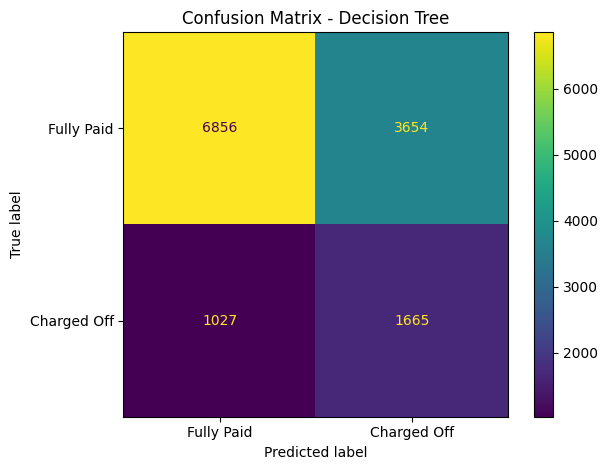

In [ ]:
# CELL 8: EVALUATE MODELS USING CONFUSION MATRICES
# Purpose:
# 1. Generate confusion matrices for both models.
# 2. Display precision, recall, and F1-score for each class.
# 3. Visualise correct and incorrect loan-default predictions.

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Create a confusion matrix for each trained model
for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)

    print(f"\n{'=' * 50}")
    print(f"CLASSIFICATION REPORT: {name}")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Fully Paid", "Charged Off"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Fully Paid", "Charged Off"]
    )

    display_plot.plot(values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

Portfolio Summary by Loan Grade:


,grade,Loan_Count,Total_Loan_Amount,Average_Loan_Amount,Default_Rate
0,A,12734,185734425.0,14585.71,5.49
1,B,20841,270439050.0,12976.30,13.49
2,C,18440,259453250.0,14070.13,23.79
3,D,8310,129101725.0,15535.71,34.95
4,E,4188,76607250.0,18292.08,44.46
5,F,1222,23581475.0,19297.44,52.37
6,G,271,4809025.0,17745.48,58.30


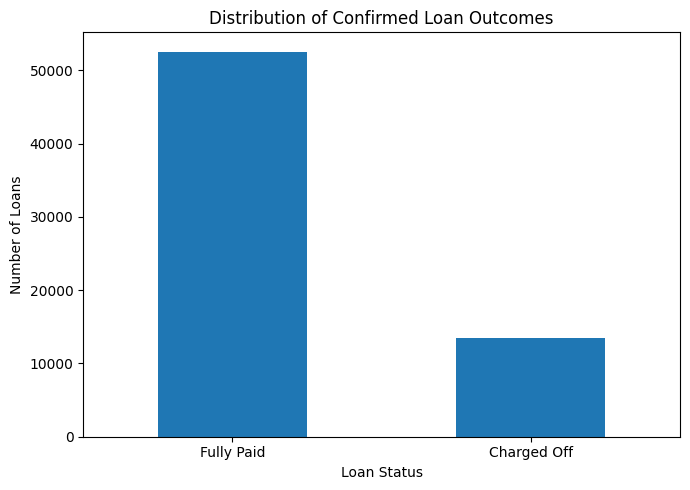


Charged-Off Rate by Loan Purpose:


,purpose,Loan_Count,Default_Rate
10,small_business,593,29.51
4,house,229,27.51
7,moving,417,24.22
6,medical,794,22.80
2,debt_consolidation,37195,22.25
8,other,3787,19.59
11,vacation,384,19.53
9,renewable_energy,37,18.92
5,major_purchase,1381,18.90
3,home_improvement,4196,18.06


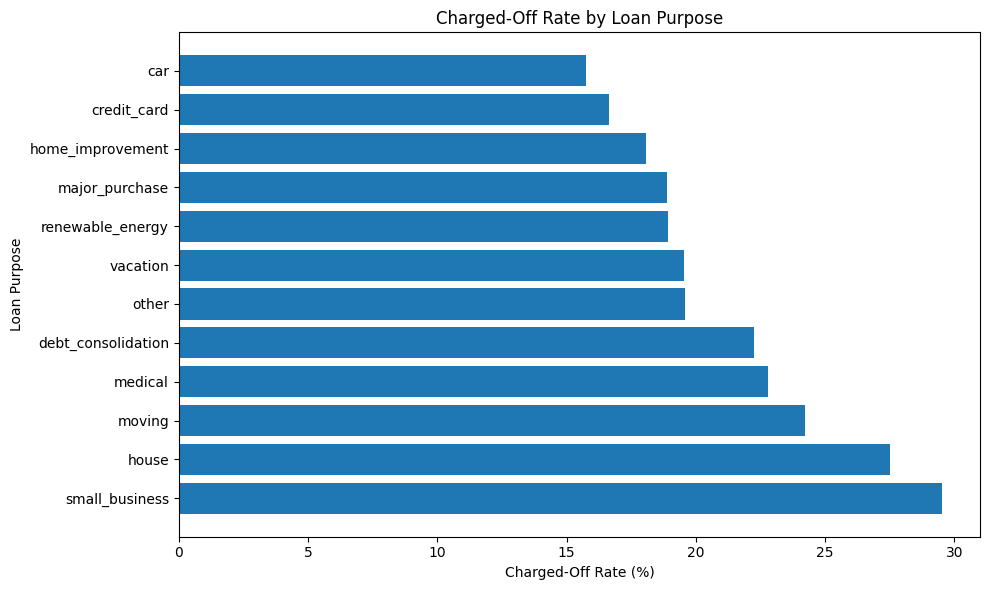

In [ ]:
# CELL 9: LOAN PORTFOLIO ANALYSIS AND VISUALISATION
# Purpose:
# 1. Analyse loan amounts by loan grade.
# 2. Visualise fully paid versus charged-off loans.
# 3. Compare charged-off rates across loan purposes.
# 4. Display portfolio-level summary statistics.

import matplotlib.pyplot as plt
import pandas as pd

# Create a copy of confirmed-outcome loans for analysis
portfolio_df = model_df.copy()

# 1. Calculate total loan amount and average loan amount by grade
grade_summary = portfolio_df.groupby("grade").agg(
    Loan_Count=("loan_amnt", "count"),
    Total_Loan_Amount=("loan_amnt", "sum"),
    Average_Loan_Amount=("loan_amnt", "mean"),
    Default_Rate=("default_flag", "mean")
).reset_index()

grade_summary["Default_Rate"] *= 100

print("Portfolio Summary by Loan Grade:")
display(grade_summary.round(2))

# 2. Visualise loan status distribution
status_counts = portfolio_df["loan_status"].value_counts()

plt.figure(figsize=(7, 5))
status_counts.plot(kind="bar")
plt.title("Distribution of Confirmed Loan Outcomes")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Visualise charged-off rate by loan purpose
purpose_summary = portfolio_df.groupby("purpose").agg(
    Loan_Count=("default_flag", "size"),
    Default_Rate=("default_flag", "mean")
).reset_index()

purpose_summary["Default_Rate"] *= 100
purpose_summary = purpose_summary.sort_values(
    "Default_Rate", ascending=False
)

print("\nCharged-Off Rate by Loan Purpose:")
display(purpose_summary.round(2))

plt.figure(figsize=(10, 6))
plt.barh(
    purpose_summary["purpose"],
    purpose_summary["Default_Rate"]
)
plt.title("Charged-Off Rate by Loan Purpose")
plt.xlabel("Charged-Off Rate (%)")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

In [ ]:
# CELL 10: DESIGN THE LOAN DATA WAREHOUSE
# Purpose:
# 1. Create a loan fact table with loan measures and keys.
# 2. Create borrower, loan and date dimension tables.
# 3. Assign surrogate keys to dimension records.
# 4. Display the resulting star-schema tables.
# 5. Keep only the selected fields required for the warehouse prototype.

import pandas as pd

# Start from confirmed loan outcomes
warehouse_source = model_df.copy().reset_index(drop=True)

# Create a unique warehouse loan key
warehouse_source["loan_key"] = range(
    1, len(warehouse_source) + 1
)

# Create date dimension from issue date
date_source = pd.to_datetime(
    warehouse_source["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

dim_date = pd.DataFrame({
    "issue_date": date_source.dropna().drop_duplicates()
})

dim_date["date_key"] = (
    dim_date["issue_date"].dt.year * 100
    + dim_date["issue_date"].dt.month
)

dim_date["year"] = dim_date["issue_date"].dt.year
dim_date["month"] = dim_date["issue_date"].dt.month

dim_date = dim_date.reset_index(drop=True)

# Create loan dimension
loan_dimension_columns = [
    "term", "grade", "sub_grade", "purpose",
    "home_ownership", "application_type"
]

dim_loan = (
    warehouse_source[loan_dimension_columns]
    .drop_duplicates()
    .reset_index(drop=True)
)

dim_loan["loan_dim_key"] = range(1, len(dim_loan) + 1)

# Create borrower dimension
borrower_dimension_columns = [
    "annual_inc", "emp_length", "verification_status",
    "addr_state", "dti", "fico_range_low",
    "fico_range_high"
]

dim_borrower = (
    warehouse_source[borrower_dimension_columns]
    .drop_duplicates()
    .reset_index(drop=True)
)

dim_borrower["borrower_dim_key"] = range(
    1, len(dim_borrower) + 1
)

# Map dimension keys to fact records
warehouse_source = warehouse_source.merge(
    dim_loan,
    on=loan_dimension_columns,
    how="left"
)

warehouse_source = warehouse_source.merge(
    dim_borrower,
    on=borrower_dimension_columns,
    how="left"
)

# Map date keys to fact records
warehouse_source["issue_date"] = date_source

date_key_map = dim_date.set_index("issue_date")["date_key"]

warehouse_source["date_key"] = (
    warehouse_source["issue_date"].map(date_key_map)
)

# Create loan fact table
fact_loan = warehouse_source[[
    "loan_key",
    "loan_dim_key",
    "borrower_dim_key",
    "date_key",
    "loan_amnt",
    "funded_amnt",
    "int_rate",
    "installment",
    "default_flag"
]].copy()

print("DATA WAREHOUSE CREATED")
print("Fact table shape:", fact_loan.shape)
print("Loan dimension shape:", dim_loan.shape)
print("Borrower dimension shape:", dim_borrower.shape)
print("Date dimension shape:", dim_date.shape)

print("\nFact Loan Table:")
display(fact_loan.head())

print("\nLoan Dimension:")
display(dim_loan.head())

print("\nBorrower Dimension:")
display(dim_borrower.head())

print("\nDate Dimension:")
display(dim_date.head())

DATA WAREHOUSE CREATED
Fact table shape: (66006, 9)
Loan dimension shape: (1663, 7)
Borrower dimension shape: (66003, 8)
Date dimension shape: (2, 4)

Fact Loan Table:


,loan_key,loan_dim_key,borrower_dim_key,date_key,loan_amnt,funded_amnt,int_rate,installment,default_flag
0,1,1,1,201512,3600.0,3600.0,13.99,123.03,0
1,2,2,2,201512,24700.0,24700.0,11.99,820.28,0
2,3,3,3,201512,20000.0,20000.0,10.78,432.66,0
3,4,4,4,201512,10400.0,10400.0,22.45,289.91,0
4,5,5,5,201512,11950.0,11950.0,13.44,405.18,0



Loan Dimension:


,term,grade,sub_grade,purpose,home_ownership,application_type,loan_dim_key
0,36 months,C,C4,debt_consolidation,MORTGAGE,Individual,1
1,36 months,C,C1,small_business,MORTGAGE,Individual,2
2,60 months,B,B4,home_improvement,MORTGAGE,Joint App,3
3,60 months,F,F1,major_purchase,MORTGAGE,Individual,4
4,36 months,C,C3,debt_consolidation,RENT,Individual,5



Borrower Dimension:


,annual_inc,emp_length,verification_status,addr_state,dti,fico_range_low,fico_range_high,borrower_dim_key
0,55000.0,10+ years,Not Verified,PA,5.91,675.0,679.0,1
1,65000.0,10+ years,Not Verified,SD,16.06,715.0,719.0,2
2,63000.0,10+ years,Not Verified,IL,10.78,695.0,699.0,3
3,104433.0,3 years,Source Verified,PA,25.37,695.0,699.0,4
4,34000.0,4 years,Source Verified,GA,10.20,690.0,694.0,5



Date Dimension:


,issue_date,date_key,year,month
0,2015-12-01,201512,2015,12
1,2015-11-01,201511,2015,11


In [ ]:
# CELL 11: PERFORM OLAP OPERATIONS ON THE LOAN WAREHOUSE
# Purpose:
# 1. Roll-up: Summarise loan amounts and defaults by grade.
# 2. Drill-down: Analyse loan outcomes by year and month.
# 3. Slice: Filter the warehouse for Grade C loans.
# 4. Dice: Filter loans by grade, purpose, and loan amount.
# 5. Display the results of each OLAP operation.

# ROLL-UP: Aggregate loan data by grade
rollup_result = fact_loan.merge(
    dim_loan[["loan_dim_key", "grade"]],
    on="loan_dim_key",
    how="left"
)

rollup_result = rollup_result.groupby("grade").agg(
    Total_Loans=("loan_key", "count"),
    Total_Loan_Amount=("loan_amnt", "sum"),
    Average_Loan_Amount=("loan_amnt", "mean"),
    Charged_Off_Count=("default_flag", "sum")
).reset_index()

rollup_result["Charged_Off_Rate"] = (
    rollup_result["Charged_Off_Count"]
    / rollup_result["Total_Loans"] * 100
)

print("1. ROLL-UP: Loan Summary by Grade")
display(rollup_result.round(2))


# DRILL-DOWN: Analyse loan outcomes by year and month
drilldown_result = fact_loan.merge(
    dim_date[["date_key", "year", "month"]],
    on="date_key",
    how="left"
)

drilldown_result = drilldown_result.groupby(
    ["year", "month"]
).agg(
    Total_Loans=("loan_key", "count"),
    Total_Loan_Amount=("loan_amnt", "sum"),
    Charged_Off_Count=("default_flag", "sum")
).reset_index()

print("\n2. DRILL-DOWN: Loan Summary by Year and Month")
display(drilldown_result.head(15).round(2))


# SLICE: Select loans belonging to Grade C
slice_result = rollup_result[
    rollup_result["grade"] == "C"
]

print("\n3. SLICE: Grade C Loan Summary")
display(slice_result.round(2))


# DICE: Select Grade B/C loans for debt consolidation
# with loan amounts between 5,000 and 20,000
dice_result = fact_loan.merge(
    dim_loan[["loan_dim_key", "grade", "purpose"]],
    on="loan_dim_key",
    how="left"
)

dice_result = dice_result[
    dice_result["grade"].isin(["B", "C"])
    & (dice_result["purpose"] == "debt_consolidation")
    & dice_result["loan_amnt"].between(5000, 20000)
]

print("\n4. DICE: Grade B/C, Debt Consolidation, Loan Amount 5,000–20,000")
print("Filtered loan records:", len(dice_result))
display(dice_result.head(10))

1. ROLL-UP: Loan Summary by Grade


,grade,Total_Loans,Total_Loan_Amount,Average_Loan_Amount,Charged_Off_Count,Charged_Off_Rate
0,A,12734,185734425.0,14585.71,699,5.49
1,B,20841,270439050.0,12976.30,2811,13.49
2,C,18440,259453250.0,14070.13,4386,23.79
3,D,8310,129101725.0,15535.71,2904,34.95
4,E,4188,76607250.0,18292.08,1862,44.46
5,F,1222,23581475.0,19297.44,640,52.37
6,G,271,4809025.0,17745.48,158,58.30



2. DRILL-DOWN: Loan Summary by Year and Month


,year,month,Total_Loans,Total_Loan_Amount,Charged_Off_Count
0,2015,11,27005,389488075.0,5324
1,2015,12,39001,560238125.0,8136



3. SLICE: Grade C Loan Summary


,grade,Total_Loans,Total_Loan_Amount,Average_Loan_Amount,Charged_Off_Count,Charged_Off_Rate
2,C,18440,259453250.0,14070.13,4386,23.79



4. DICE: Grade B/C, Debt Consolidation, Loan Amount 5,000–20,000
Filtered loan records: 15919


,loan_key,loan_dim_key,borrower_dim_key,date_key,loan_amnt,funded_amnt,int_rate,installment,default_flag,grade,purpose
4,5,5,5,201512,11950.0,11950.0,13.44,405.18,0,C,debt_consolidation
5,6,6,6,201512,20000.0,20000.0,9.17,637.58,0,B,debt_consolidation
14,15,15,15,201512,18000.0,18000.0,11.99,400.31,0,C,debt_consolidation
28,29,28,29,201512,12000.0,12000.0,10.78,391.62,0,B,debt_consolidation
37,38,36,38,201512,20000.0,20000.0,9.80,643.47,0,B,debt_consolidation
47,48,6,48,201512,7200.0,7200.0,9.17,229.53,0,B,debt_consolidation
53,54,48,54,201512,20000.0,20000.0,12.88,672.73,0,C,debt_consolidation
54,55,49,55,201512,14000.0,14000.0,14.85,331.96,1,C,debt_consolidation
55,56,50,56,201512,20000.0,20000.0,13.99,465.27,1,C,debt_consolidation
64,65,58,65,201512,15000.0,15000.0,10.78,324.50,0,B,debt_consolidation


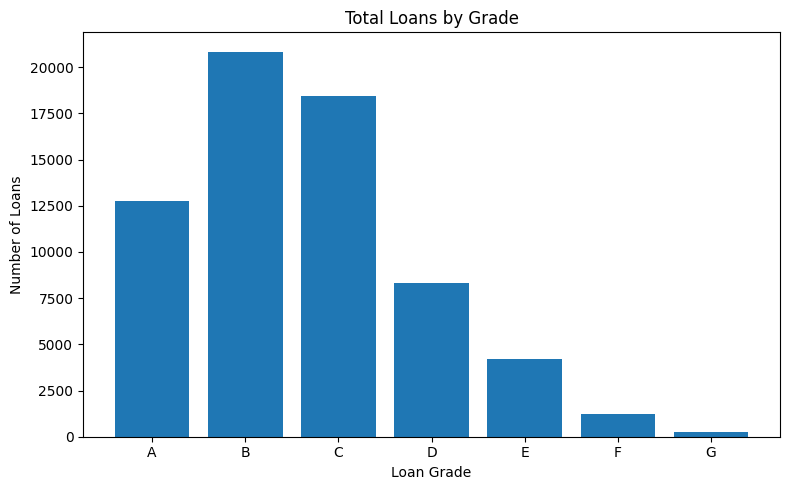

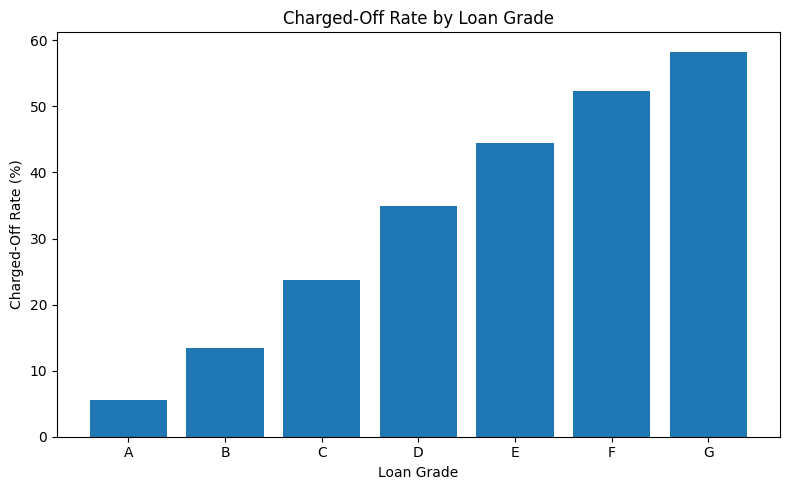

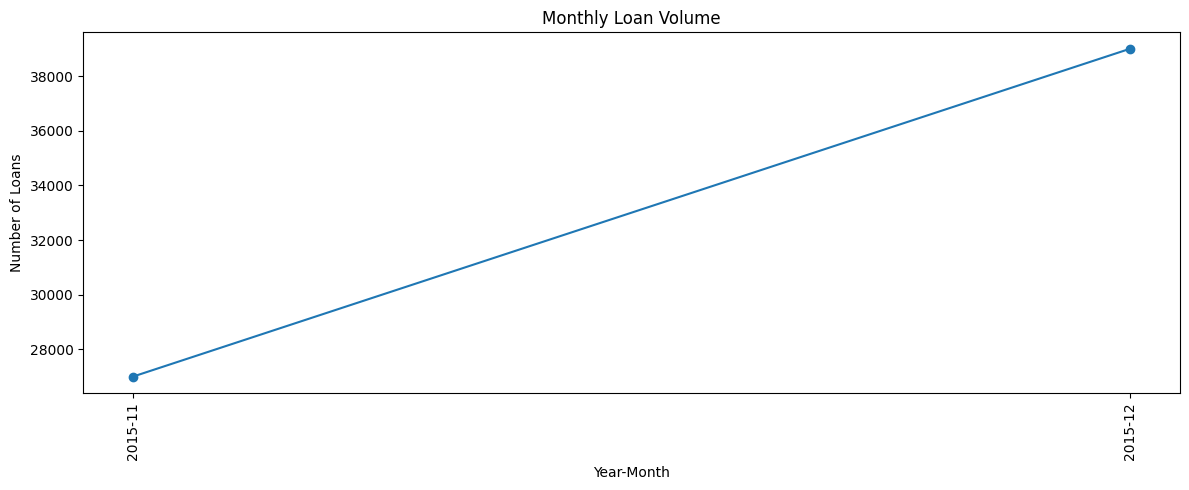

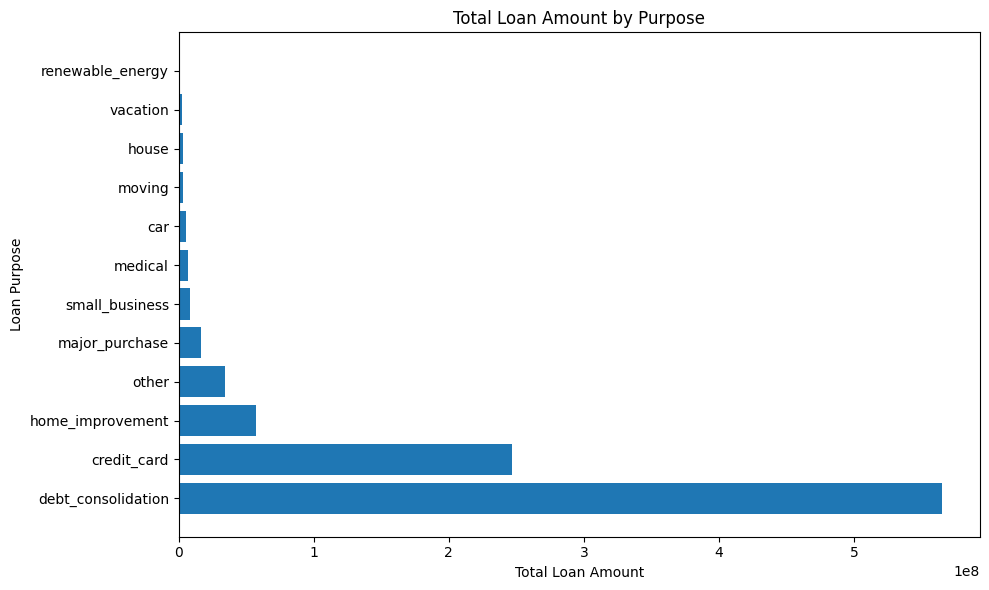

In [ ]:
# CELL 12: VISUALISE OLAP ANALYSIS RESULTS
# Purpose:
# 1. Plot total loans across loan grades.
# 2. Compare charged-off rates across grades.
# 3. Visualise monthly loan volume.
# 4. Show loan amounts across different purposes.

import matplotlib.pyplot as plt
import pandas as pd

# 1. Roll-up: Number of loans by grade
plt.figure(figsize=(8, 5))
plt.bar(rollup_result["grade"], rollup_result["Total_Loans"])
plt.title("Total Loans by Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()

# 2. Charged-off rate by grade
plt.figure(figsize=(8, 5))
plt.bar(rollup_result["grade"], rollup_result["Charged_Off_Rate"])
plt.title("Charged-Off Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Charged-Off Rate (%)")
plt.tight_layout()
plt.show()

# 3. Drill-down: Monthly loan volume
monthly_summary = drilldown_result.copy()
monthly_summary["Year-Month"] = (
    monthly_summary["year"].astype("Int64").astype(str)
    + "-"
    + monthly_summary["month"].astype("Int64").astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Year-Month"],
    monthly_summary["Total_Loans"],
    marker="o"
)
plt.title("Monthly Loan Volume")
plt.xlabel("Year-Month")
plt.ylabel("Number of Loans")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 4. Total loan amount by purpose
purpose_chart = (
    portfolio_df.groupby("purpose")["loan_amnt"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
plt.barh(purpose_chart.index, purpose_chart.values)
plt.title("Total Loan Amount by Purpose")
plt.xlabel("Total Loan Amount")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

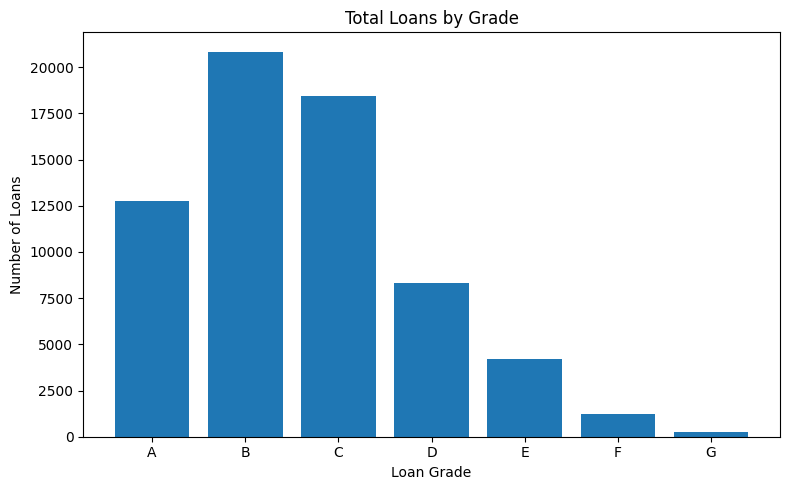

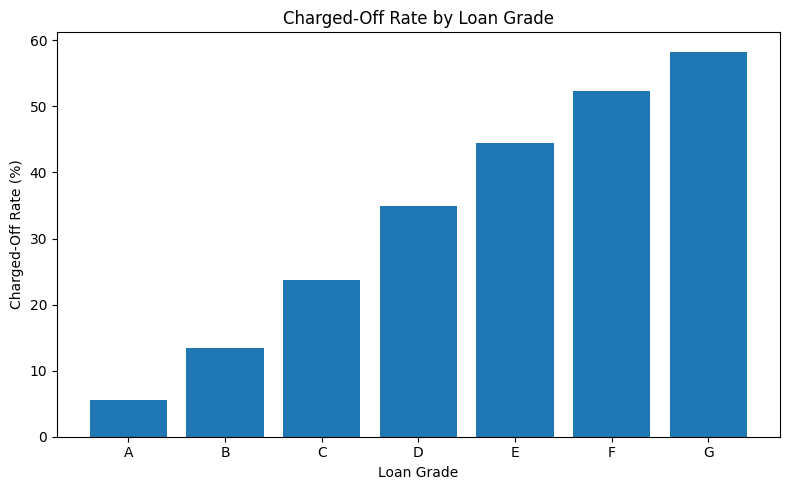

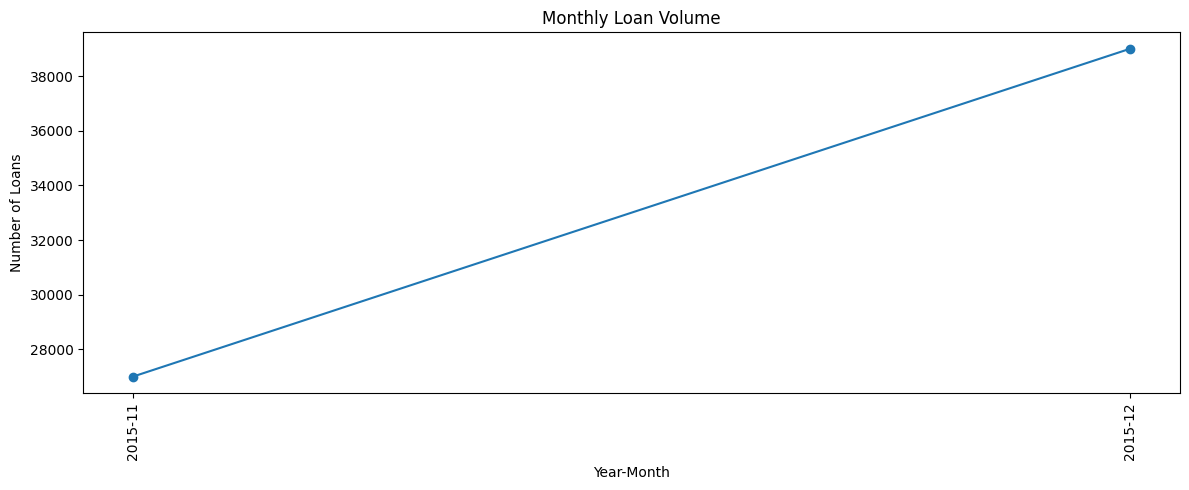

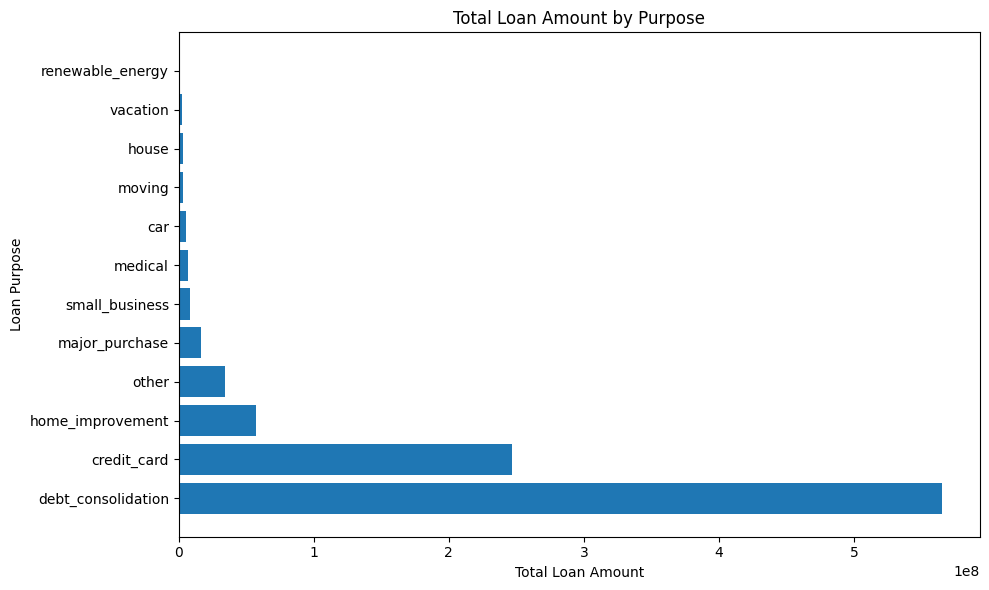

In [ ]:
# CELL 12: VISUALISE OLAP ANALYSIS RESULTS
# Purpose:
# 1. Plot total loans across loan grades.
# 2. Compare charged-off rates across grades.
# 3. Visualise monthly loan volume.
# 4. Show loan amounts across different purposes.

import matplotlib.pyplot as plt
import pandas as pd

# 1. Roll-up: Number of loans by grade
plt.figure(figsize=(8, 5))
plt.bar(rollup_result["grade"], rollup_result["Total_Loans"])
plt.title("Total Loans by Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()

# 2. Charged-off rate by grade
plt.figure(figsize=(8, 5))
plt.bar(rollup_result["grade"], rollup_result["Charged_Off_Rate"])
plt.title("Charged-Off Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Charged-Off Rate (%)")
plt.tight_layout()
plt.show()

# 3. Drill-down: Monthly loan volume
monthly_summary = drilldown_result.copy()
monthly_summary["Year-Month"] = (
    monthly_summary["year"].astype("Int64").astype(str)
    + "-"
    + monthly_summary["month"].astype("Int64").astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Year-Month"],
    monthly_summary["Total_Loans"],
    marker="o"
)
plt.title("Monthly Loan Volume")
plt.xlabel("Year-Month")
plt.ylabel("Number of Loans")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 4. Total loan amount by purpose
purpose_chart = (
    portfolio_df.groupby("purpose")["loan_amnt"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
plt.barh(purpose_chart.index, purpose_chart.values)
plt.title("Total Loan Amount by Purpose")
plt.xlabel("Total Loan Amount")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()

In [ ]:
# CELL 13: EXPORT PROJECT OUTPUTS AND CREATE A ZIP FILE
# Purpose:
# 1. Export the loan fact table and dimension tables as CSV files.
# 2. Export model evaluation and OLAP analysis results.
# 3. Save all output files in one project folder.
# 4. Create a ZIP archive for easy download and submission.

import os
import zipfile
from google.colab import files

# Create an output directory
output_dir = "/content/Banking_Intelligence_Project"
os.makedirs(output_dir, exist_ok=True)

# Export warehouse tables
fact_loan.to_csv(
    os.path.join(output_dir, "fact_loan.csv"), index=False
)
dim_loan.to_csv(
    os.path.join(output_dir, "dim_loan.csv"), index=False
)
dim_borrower.to_csv(
    os.path.join(output_dir, "dim_borrower.csv"), index=False
)
dim_date.to_csv(
    os.path.join(output_dir, "dim_date.csv"), index=False
)

# Export model comparison
results_df.to_csv(
    os.path.join(output_dir, "model_comparison.csv"), index=False
)

# Export OLAP summaries
rollup_result.to_csv(
    os.path.join(output_dir, "olap_rollup_by_grade.csv"), index=False
)
drilldown_result.to_csv(
    os.path.join(output_dir, "olap_drilldown_by_month.csv"), index=False
)
dice_result.to_csv(
    os.path.join(output_dir, "olap_dice_results.csv"), index=False
)

# Export portfolio summaries
grade_summary.to_csv(
    os.path.join(output_dir, "portfolio_by_grade.csv"), index=False
)
purpose_summary.to_csv(
    os.path.join(output_dir, "portfolio_by_purpose.csv"), index=False
)

# Create ZIP archive
zip_path = "/content/Banking_Intelligence_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(output_dir):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, output_dir)
            zipf.write(full_path, relative_path)

print("Project outputs exported successfully.")
print("Files created:", len(os.listdir(output_dir)))
print("ZIP archive:", zip_path)

# Download the ZIP archive
files.download(zip_path)

Project outputs exported successfully.
Files created: 10
ZIP archive: /content/Banking_Intelligence_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>